# Tuning and final model (Ludovico)

**Goal:** tune the three models shortlisted in `models_ludovico`, check that the gains are real, choose the final model and produce its submission.

| Model | Recipe (from `models_ludovico`) | Untuned ROC AUC | What is tuned |
|---|---|---|---|
| Logistic regression | Ludovico, linear | 0.785 (0.796 with L1 = V03) | `C` of the model, L1 selection and its `C` |
| KNN | Ludovico, linear | 0.776 | `k`, weighting of the neighbours, L1 selection |
| Gradient boosting | Ludovico, tree | 0.774 | learning rate, trees, leaves, leaf size, regularisation, share of features |

**The result to beat is V03:** ROC AUC 0.796, honest F1 0.802, Kaggle 0.804.

<div class="alert alert-block alert-info">

# TOC<a class="anchor" id="toc"></a>
* [<font color='#E8800A'>Setup</font>](#setup)
* [<font color='#E8800A'>1. Method</font>](#method)
* [<font color='#E8800A'>2. Logistic regression</font>](#lr)
* [<font color='#E8800A'>3. KNN</font>](#knn)
* [<font color='#E8800A'>4. Gradient boosting</font>](#gb)
* [<font color='#E8800A'>5. Blends of the tuned models</font>](#blend)
* [<font color='#E8800A'>6. Check on 8 half-year folds</font>](#check)
* [<font color='#E8800A'>7. Final choice</font>](#final)
* [<font color='#E8800A'>8. Submission</font>](#submit)
* [<font color='#E8800A'>9. Summary</font>](#summary)
* [<font color='#E8800A'>10. Exploratory submission: the blend</font>](#explore)

</div>

# <font color='#E8800A'>Setup</font> <a class="anchor" id="setup"></a>
[Back to TOC](#toc)

`%run` executes `models_ludovico.ipynb` (about 3 minutes, it runs preprocessing, validation and cleaning first). It gives back the recipes, the five models, V03, `fold_auc` (the untuned scores per fold), `paired` and `honest_f1`.

In [1]:
%%capture
%run ./models_ludovico.ipynb

In [2]:
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import RandomizedSearchCV

from src.submissions import check_submission, publish, record_kaggle_score, submission_path, submit

N_FOLDS = len(official_folds)

# <font color='#E8800A'>1. Method</font> <a class="anchor" id="method"></a>
[Back to TOC](#toc)

**Search.** Every configuration is scored on the **official folds** (ROC AUC, every step refitted on each training fold): a full grid for the two fast models, 40 random configurations for gradient boosting.

**The winner's curse.** The best of many configurations is partly the luckiest: with 3 folds, its score is optimistic. Two protections:
1. **Paired comparison with the untuned model** on the same folds, read at 2 SEM, as in every previous notebook.
2. **A second check on 8 half-year folds** (`prep_folds`, §6): the tuned pipelines were not chosen on them. They overlap the official folds in time, so they are not a fresh test, but a gain that holds on 8 different cuts is unlikely to be luck.

**Final rule, declared before the results.** A candidate replaces V03 only if it is **better than V03 beyond 2 SEM on the official folds** and **not worse on the 8 half-year folds**. Otherwise V03 stays the final model: it is simple and already confirmed on Kaggle.

In [3]:
def search_scores(search, describe):
    """One row per configuration: mean ROC AUC, per-fold scores, readable label; best first."""
    res = search.cv_results_
    folds = np.array([res[f"split{k}_test_score"] for k in range(N_FOLDS)]).T
    table = pd.DataFrame({"configuration": [describe(p) for p in res["params"]], "ROC AUC": folds.mean(axis=1),
                          "fold 1 / 2 / 3": [" / ".join(f"{v:.3f}" for v in row) for row in folds]})
    table["params"] = res["params"]
    table["folds"] = list(folds)
    return table.sort_values("ROC AUC", ascending=False).reset_index(drop=True)


def describe(params):
    """Readable label of a configuration."""
    parts = []
    for key, value in params.items():
        if key == "select":
            value = "none" if value == "passthrough" else f"L1 C={value.estimator.named_steps['logisticregression'].C}"
        parts.append(f"{key.replace('model__', '')}={value}")
    return ", ".join(parts)


def show_top(table, untuned_folds, n=8):
    """Top configurations, each compared with the untuned model fold by fold."""
    top = table.head(n).copy()
    stats = pd.DataFrame([paired(f, untuned_folds) for f in top["folds"]], index=top.index)
    out = pd.concat([top[["configuration", "ROC AUC", "fold 1 / 2 / 3"]], stats.add_suffix(" vs untuned")], axis=1)
    return out.style.format({"ROC AUC": "{:.4f}", "diff vs untuned": "{:+.4f}", "SEM vs untuned": "{:.4f}",
                             "diff / SEM vs untuned": "{:+.1f}"})


def with_l1(c):
    return clone(l1_selector).set_params(estimator__logisticregression__C=c)


tuned, tuned_folds = {}, {}   # name -> tuned pipeline / its per-fold ROC AUC on the official folds

# <font color='#E8800A'>2. Logistic regression</font> <a class="anchor" id="lr"></a>
[Back to TOC](#toc)

The V03 pipeline with two knobs: `C` of the logistic regression (smaller = stronger penalty) and the L1 selection (none, or `C` from 0.02 to 0.2: smaller = fewer columns kept). V03 is the point `C=1, L1 C=0.05`. 6 × 6 = 36 configurations.

In [4]:
lr_search = GridSearchCV(
    v03_pipeline(),
    {"model__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0],
     "select": ["passthrough"] + [with_l1(c) for c in [0.02, 0.03, 0.05, 0.1, 0.2]]},
    cv=official_folds, scoring="roc_auc", refit=False, n_jobs=-1,
).fit(X_full, y)

lr_table = search_scores(lr_search, describe)
show_top(lr_table, fold_auc[V03, "Ludovico"])  # compared with V03 itself

,configuration,ROC AUC,fold 1 / 2 / 3,diff vs untuned,SEM vs untuned,diff / SEM vs untuned,folds won vs untuned
0,"C=0.03, select=L1 C=0.02",0.7994,0.790 / 0.802 / 0.806,+0.0036,0.0049,+0.7,2/3
1,"C=0.03, select=L1 C=0.05",0.7991,0.783 / 0.807 / 0.807,+0.0033,0.0017,+1.9,2/3
2,"C=0.1, select=L1 C=0.02",0.7989,0.788 / 0.803 / 0.806,+0.0031,0.0040,+0.8,2/3
3,"C=0.01, select=L1 C=0.05",0.7984,0.785 / 0.804 / 0.806,+0.0026,0.0029,+0.9,2/3
4,"C=0.3, select=L1 C=0.02",0.7983,0.788 / 0.803 / 0.804,+0.0025,0.0037,+0.7,2/3
5,"C=0.03, select=L1 C=0.03",0.7983,0.783 / 0.807 / 0.805,+0.0025,0.0015,+1.6,2/3
6,"C=0.01, select=L1 C=0.02",0.7981,0.791 / 0.799 / 0.805,+0.0023,0.0060,+0.4,2/3
7,"C=1.0, select=L1 C=0.02",0.7980,0.787 / 0.803 / 0.803,+0.0022,0.0037,+0.6,2/3


In [5]:
heat = lr_table.assign(
    C=[p["model__C"] for p in lr_table["params"]],
    selection=[describe({"select": p["select"]}).split("=", 1)[1] for p in lr_table["params"]],
).pivot(index="selection", columns="C", values="ROC AUC")
heat.style.format("{:.4f}").background_gradient(cmap="Blues", axis=None)

C,0.010000,0.030000,0.100000,0.300000,1.000000,3.000000
selection,,,,,,
L1 C=0.02,0.7981,0.7994,0.7989,0.7983,0.7980,0.7978
L1 C=0.03,0.7977,0.7983,0.7972,0.7959,0.7953,0.7951
L1 C=0.05,0.7984,0.7991,0.7979,0.7965,0.7958,0.7955
L1 C=0.1,0.7949,0.7961,0.7949,0.7939,0.7932,0.7929
L1 C=0.2,0.7954,0.7968,0.7961,0.7954,0.7948,0.7947
none,0.7946,0.7936,0.7906,0.7877,0.7851,0.7843


In [6]:
tuned["logistic regression"] = clone(v03_pipeline()).set_params(**lr_table.loc[0, "params"])
tuned_folds["logistic regression"] = lr_table.loc[0, "folds"]
print("chosen:", lr_table.loc[0, "configuration"])

chosen: C=0.03, select=L1 C=0.02


**Reading**

- **The best configuration is `C=0.03` with L1 `C=0.02`:** 0.7994 against 0.7958 for V03 (`C=1`, L1 `C=0.05`), +0.0036 ± 0.0049, ratio 0.7: **inside the noise.**
- **The heat map shows a flat surface:** every configuration with L1 selection is between 0.793 and 0.799. A stronger penalty (smaller `C`) helps a little, mostly without selection: from 0.785 (`C=1`) to 0.795 (`C=0.01`). Penalising the coefficients and dropping columns do similar jobs.
- **Selection still matters:** the "none" row is the lowest at every `C`.
- Reading: V03 was already close to the best the logistic regression can do on these features.

# <font color='#E8800A'>3. KNN</font> <a class="anchor" id="knn"></a>
[Back to TOC](#toc)

`k` from 15 to 200, neighbours weighted equally or by closeness (`distance`), with or without L1 selection (in a distance every column counts equally, so dropping weak columns may help). 6 × 2 × 2 = 24 configurations.

In [7]:
knn_steps = ludovico_recipe(KNeighborsClassifier(), "linear").steps
knn_base = Pipeline([*knn_steps[:-1], ("select", "passthrough"), knn_steps[-1]])

knn_search = GridSearchCV(
    knn_base,
    {"model__n_neighbors": [15, 25, 50, 100, 150, 200], "model__weights": ["uniform", "distance"],
     "select": ["passthrough", with_l1(0.05)]},
    cv=official_folds, scoring="roc_auc", refit=False, n_jobs=-1,
).fit(X_full, y)

knn_table = search_scores(knn_search, describe)
show_top(knn_table, fold_auc["KNN (k=25)", "Ludovico"])

,configuration,ROC AUC,fold 1 / 2 / 3,diff vs untuned,SEM vs untuned,diff / SEM vs untuned,folds won vs untuned
0,"n_neighbors=100, weights=distance, select=none",0.7892,0.794 / 0.776 / 0.797,+0.0134,0.0050,+2.7,3/3
1,"n_neighbors=200, weights=distance, select=L1 C=0.05",0.7891,0.781 / 0.790 / 0.796,+0.0133,0.0031,+4.2,3/3
2,"n_neighbors=150, weights=distance, select=none",0.7884,0.796 / 0.776 / 0.793,+0.0125,0.0055,+2.3,3/3
3,"n_neighbors=150, weights=distance, select=L1 C=0.05",0.7883,0.776 / 0.792 / 0.797,+0.0125,0.0050,+2.5,3/3
4,"n_neighbors=100, weights=uniform, select=none",0.7880,0.795 / 0.774 / 0.795,+0.0122,0.0057,+2.1,3/3
5,"n_neighbors=50, weights=distance, select=none",0.7874,0.789 / 0.776 / 0.797,+0.0116,0.0037,+3.1,3/3
6,"n_neighbors=200, weights=uniform, select=L1 C=0.05",0.7873,0.782 / 0.787 / 0.793,+0.0115,0.0018,+6.2,3/3
7,"n_neighbors=150, weights=uniform, select=none",0.7870,0.796 / 0.774 / 0.791,+0.0112,0.0061,+1.8,3/3


In [8]:
tuned["KNN"] = clone(knn_base).set_params(**knn_table.loc[0, "params"])
tuned_folds["KNN"] = knn_table.loc[0, "folds"]
print("chosen:", knn_table.loc[0, "configuration"])

chosen: n_neighbors=100, weights=distance, select=none


**Reading**

- **Tuning helps KNN clearly:** `k=100`, neighbours weighted by distance, no selection: 0.789 against 0.776 untuned (k=25), +0.013 ± 0.005, better on every fold.
- **Larger `k` is better up to about 100–200:** with k=25 each probability rests on few neighbours and is noisy.
- **Still below V03** (−0.007, inside the noise) and below the other two tuned models.

# <font color='#E8800A'>4. Gradient boosting</font> <a class="anchor" id="gb"></a>
[Back to TOC](#toc)

Six knobs, 3–4 values each (about 2,000 combinations), so **40 random configurations** instead of the full grid.

| Knob | Values | Effect |
|---|---|---|
| `learning_rate` | 0.02, 0.05, 0.1 | how much each tree corrects the previous ones |
| `max_iter` | 100, 200, 400 | number of trees |
| `max_leaf_nodes` | 7, 15, 31 | size of each tree |
| `min_samples_leaf` | 20, 50, 100, 200 | rows needed in a leaf: larger = smoother |
| `l2_regularization` | 0, 1, 10 | penalty on the leaf values |
| `max_features` | 0.5, 0.8, 1.0 | share of columns each split may look at |

In [9]:
gb_base = ludovico_recipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE), "tree")

gb_search = RandomizedSearchCV(
    gb_base,
    {"model__learning_rate": [0.02, 0.05, 0.1], "model__max_iter": [100, 200, 400],
     "model__max_leaf_nodes": [7, 15, 31], "model__min_samples_leaf": [20, 50, 100, 200],
     "model__l2_regularization": [0.0, 1.0, 10.0], "model__max_features": [0.5, 0.8, 1.0]},
    n_iter=40, cv=official_folds, scoring="roc_auc", refit=False, n_jobs=-1, random_state=RANDOM_STATE,
).fit(X_full, y)

gb_table = search_scores(gb_search, describe)
show_top(gb_table, fold_auc["gradient boosting", "Ludovico"])

,configuration,ROC AUC,fold 1 / 2 / 3,diff vs untuned,SEM vs untuned,diff / SEM vs untuned,folds won vs untuned
0,"min_samples_leaf=200, max_leaf_nodes=31, max_iter=100, max_features=0.5, learning_rate=0.05, l2_regularization=10.0",0.8019,0.789 / 0.805 / 0.812,+0.0277,0.0065,+4.2,3/3
1,"min_samples_leaf=200, max_leaf_nodes=7, max_iter=200, max_features=1.0, learning_rate=0.02, l2_regularization=1.0",0.8007,0.787 / 0.803 / 0.812,+0.0265,0.0060,+4.4,3/3
2,"min_samples_leaf=100, max_leaf_nodes=7, max_iter=400, max_features=1.0, learning_rate=0.02, l2_regularization=1.0",0.8007,0.789 / 0.803 / 0.811,+0.0265,0.0063,+4.2,3/3
3,"min_samples_leaf=20, max_leaf_nodes=15, max_iter=100, max_features=0.8, learning_rate=0.05, l2_regularization=10.0",0.8000,0.792 / 0.798 / 0.810,+0.0258,0.0056,+4.6,3/3
4,"min_samples_leaf=100, max_leaf_nodes=15, max_iter=400, max_features=0.8, learning_rate=0.02, l2_regularization=10.0",0.8000,0.785 / 0.806 / 0.809,+0.0258,0.0080,+3.2,3/3
5,"min_samples_leaf=200, max_leaf_nodes=31, max_iter=200, max_features=0.5, learning_rate=0.02, l2_regularization=0.0",0.7997,0.785 / 0.803 / 0.811,+0.0255,0.0065,+3.9,3/3
6,"min_samples_leaf=200, max_leaf_nodes=31, max_iter=200, max_features=0.8, learning_rate=0.02, l2_regularization=0.0",0.7996,0.783 / 0.805 / 0.810,+0.0254,0.0074,+3.4,3/3
7,"min_samples_leaf=200, max_leaf_nodes=31, max_iter=400, max_features=1.0, learning_rate=0.02, l2_regularization=10.0",0.7994,0.779 / 0.809 / 0.810,+0.0252,0.0093,+2.7,3/3


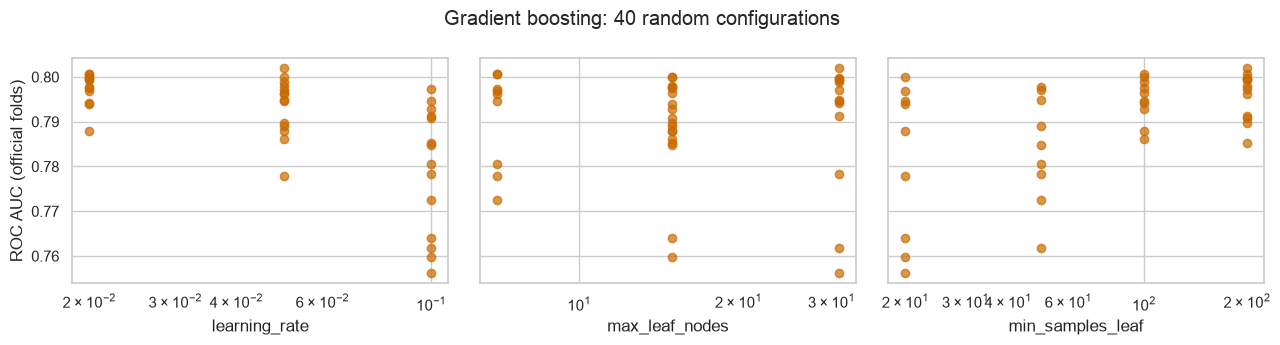

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, knob in zip(axes, ["model__learning_rate", "model__max_leaf_nodes", "model__min_samples_leaf"]):
    values = [p[knob] for p in gb_table["params"]]
    ax.scatter(values, gb_table["ROC AUC"], color=PLOT_ORANGE, alpha=0.7)
    ax.set(xlabel=knob.replace("model__", ""), xscale="log")
axes[0].set_ylabel("ROC AUC (official folds)")
fig.suptitle("Gradient boosting: 40 random configurations")
plt.tight_layout()
plt.show()

In [11]:
tuned["gradient boosting"] = clone(gb_base).set_params(**gb_table.loc[0, "params"])
tuned_folds["gradient boosting"] = gb_table.loc[0, "folds"]
print("chosen:", gb_table.loc[0, "configuration"])

chosen: min_samples_leaf=200, max_leaf_nodes=31, max_iter=100, max_features=0.5, learning_rate=0.05, l2_regularization=10.0


**Reading**

- **Tuning helps gradient boosting the most:** 0.802 against 0.774 untuned, +0.028 ± 0.007, better on every fold.
- **The best configurations share one trait: strong regularisation.** Large leaves (`min_samples_leaf` 100–200), few or small trees with a low learning rate, L2 penalty, half the columns per split. The default (leaves of 20 rows, 100 trees at 0.1) overfits these 6,500 rows.
- **The top 8 are within 0.0025 of each other:** many configurations are equivalent, so the exact winner is partly luck (winner's curse). §6 checks it on other folds.

# <font color='#E8800A'>5. Blends of the tuned models</font> <a class="anchor" id="blend"></a>
[Back to TOC](#toc)

A **blend** averages the probabilities of several models (`VotingClassifier`, `voting="soft"`). It helps when the models make **different** mistakes: a linear model and a tree ensemble see the data in different ways. Each member keeps its own recipe, and every member is refitted inside each fold, so the blend is validated like any other pipeline.

In [12]:
BLENDS = {
    "blend: logistic + boosting": ["logistic regression", "gradient boosting"],
    "blend: logistic + boosting + KNN": ["logistic regression", "gradient boosting", "KNN"],
}
oof_tuned = {}
for name, members in BLENDS.items():
    tuned[name] = VotingClassifier([(m.split()[0], clone(tuned[m])) for m in members], voting="soft")
    scores, oof_tuned[name] = evaluate(tuned[name], official_folds, X_full, y)
    tuned_folds[name] = scores["ROC AUC"].to_numpy()

candidates = {"V03 (reference)": fold_auc[V03, "Ludovico"], **tuned_folds}
official_board = pd.DataFrame({
    name: {"ROC AUC": f.mean(), "fold 1 / 2 / 3": " / ".join(f"{v:.3f}" for v in f),
           **paired(f, fold_auc[V03, "Ludovico"])} for name, f in candidates.items()
}).T.sort_values("ROC AUC", ascending=False)
official_board.loc["V03 (reference)", ["diff", "SEM", "diff / SEM", "folds won"]] = [0.0, np.nan, np.nan, "ref"]
official_board.columns = ["ROC AUC", "fold 1 / 2 / 3", "diff vs V03", "SEM", "diff / SEM", "folds won"]
official_board.style.format({"ROC AUC": "{:.4f}", "diff vs V03": "{:+.4f}", "SEM": "{:.4f}", "diff / SEM": "{:+.1f}"},
                            na_rep="-")

,ROC AUC,fold 1 / 2 / 3,diff vs V03,SEM,diff / SEM,folds won
blend: logistic + boosting + KNN,0.8039,0.797 / 0.802 / 0.813,+0.0081,0.0069,+1.2,2/3
blend: logistic + boosting,0.8037,0.791 / 0.807 / 0.813,+0.0079,0.0044,+1.8,2/3
gradient boosting,0.8019,0.789 / 0.805 / 0.812,+0.0061,0.0045,+1.4,2/3
logistic regression,0.7994,0.790 / 0.802 / 0.806,+0.0036,0.0049,+0.7,2/3
V03 (reference),0.7958,0.779 / 0.807 / 0.801,+0.0000,-,-,ref
KNN,0.7892,0.794 / 0.776 / 0.797,-0.0066,0.0135,-0.5,1/3


**Reading**

- **Every candidate except KNN is above V03 on the official folds, but none beyond 2 SEM:**
  - blend logistic + boosting: +0.0079 ± 0.0044 (ratio 1.8, 2/3 folds);
  - blend with KNN: +0.0081 ± 0.0069 (ratio 1.2);
  - tuned boosting alone: +0.0061 ± 0.0045 (ratio 1.4).
- **The blend is the best candidate:** the linear model and the trees make partly different mistakes, so their average ranks better than either. Adding KNN adds almost nothing.

# <font color='#E8800A'>6. Check on 8 half-year folds</font> <a class="anchor" id="check"></a>
[Back to TOC](#toc)

Every candidate, V03 and the untuned versions are scored again on the 8 half-year folds of `preprocessing_ludovico` (2021 → 2025, 90-day gap). The tuned settings were chosen on the official folds, so this is a check against the winner's curse. About 2 minutes.

In [13]:
check_runs = {"V03 (reference)": v03_pipeline(),
              "logistic regression (untuned)": ludovico_recipe(LogisticRegression(max_iter=3000), "linear"),
              "KNN (untuned, k=25)": ludovico_recipe(KNeighborsClassifier(n_neighbors=25), "linear"),
              "gradient boosting (untuned)": ludovico_recipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE), "tree"),
              **tuned}
check_folds = {name: evaluate(clone(p), prep_folds, X_full, y)[0]["ROC AUC"].to_numpy()
               for name, p in check_runs.items()}

check_board = pd.DataFrame({name: {"ROC AUC (8 folds)": f.mean(), **paired(f, check_folds["V03 (reference)"])}
                            for name, f in check_folds.items()}).T.sort_values("ROC AUC (8 folds)", ascending=False)
check_board.columns = ["ROC AUC (8 folds)", "diff vs V03", "SEM", "diff / SEM", "folds won"]
for model, untuned in [("logistic regression", "logistic regression (untuned)"), ("KNN", "KNN (untuned, k=25)"),
                       ("gradient boosting", "gradient boosting (untuned)")]:
    r = paired(check_folds[model], check_folds[untuned])
    check_board.loc[model, "tuned vs untuned"] = f"{r['diff']:+.4f} ± {r['SEM']:.4f} ({r['folds won']})"
check_board.style.format({"ROC AUC (8 folds)": "{:.4f}", "diff vs V03": "{:+.4f}", "SEM": "{:.4f}",
                          "diff / SEM": "{:+.1f}"}, na_rep="-")

,ROC AUC (8 folds),diff vs V03,SEM,diff / SEM,folds won,tuned vs untuned
blend: logistic + boosting + KNN,0.8064,+0.0046,0.0032,+1.4,4/8,-
blend: logistic + boosting,0.8060,+0.0042,0.0022,+1.9,5/8,-
logistic regression,0.8028,+0.0010,0.0025,+0.4,4/8,+0.0059 ± 0.0057 (4/8)
gradient boosting,0.8018,+0.0000,0.0039,+0.0,3/8,+0.0159 ± 0.0045 (7/8)
V03 (reference),0.8018,+0.0000,0.0000,-,0/8,-
logistic regression (untuned),0.7970,-0.0048,0.0037,-1.3,3/8,-
KNN,0.7941,-0.0077,0.0059,-1.3,2/8,+0.0161 ± 0.0042 (8/8)
gradient boosting (untuned),0.7859,-0.0159,0.0073,-2.2,1/8,-
"KNN (untuned, k=25)",0.7780,-0.0238,0.0061,-3.9,1/8,-


**Reading**

- **The tuning gains hold on the 8 half-year folds for the two models that improved most:** boosting +0.016 ± 0.005 (7/8 folds), KNN +0.016 ± 0.004 (8/8). For the logistic regression the gain is smaller and inside the noise (+0.006 ± 0.006).
- **Against V03 the picture repeats:** the blend logistic + boosting is the best (+0.0042 ± 0.0022, ratio 1.9, 5/8 folds), close to the line but not beyond it. Tuned boosting alone ties V03 (+0.0000).
- **Two different fold schemes give the same ranking** (blends > tuned logistic ≈ tuned boosting ≈ V03 > KNN), which makes the ranking credible; the size of the gain over V03 stays below 2 SEM in both.

# <font color='#E8800A'>7. Final choice</font> <a class="anchor" id="final"></a>
[Back to TOC](#toc)

The rule of §1, applied by code: better than V03 beyond 2 SEM on the official folds **and** not worse on the 8 half-year folds (mean difference ≥ 0). Among the candidates that pass, the highest ROC AUC on the official folds wins. If none passes, V03 stays.

In [14]:
passed = [name for name in tuned
          if official_board.loc[name, "diff vs V03"] > 2 * official_board.loc[name, "SEM"]
          and check_board.loc[name, "diff vs V03"] >= 0]
FINAL = max(passed, key=lambda n: official_board.loc[n, "ROC AUC"]) if passed else "V03 (reference)"
final_pipeline = tuned[FINAL] if FINAL in tuned else v03_pipeline()

print("candidates that pass the rule:", passed or "none")
print("FINAL MODEL:", FINAL)

candidates that pass the rule: none
FINAL MODEL: V03 (reference)


**Threshold and honest F1**, with the same rules as every submission:
- **final threshold:** best F1 on the out-of-fold predictions of all official folds;
- **honest F1:** threshold chosen on folds 1–2, F1 on fold 3. This is the number to compare with Kaggle.

In [15]:
final_scores, final_oof = evaluate(final_pipeline, official_folds, X_full, y)
covered = final_oof.notna()
FINAL_THRESHOLD, f1_curve = best_threshold(y[covered], final_oof[covered])
final_f1, t_early = honest_f1(final_oof)

pd.Series({"ROC AUC (official folds)": f"{final_scores['ROC AUC'].mean():.4f}",
           "final threshold (all folds)": f"{FINAL_THRESHOLD:.2f}",
           "threshold from folds 1-2": f"{t_early:.2f}",
           "honest F1 (fold 3)": f"{final_f1:.3f}",
           "F1 always 1 (fold 3)": f"{FLOOR:.3f}",
           "V03 for comparison": "honest F1 0.802, Kaggle 0.804"}, name=FINAL).to_frame()

,V03 (reference)
ROC AUC (official folds),0.7958
final threshold (all folds),0.43
threshold from folds 1-2,0.43
honest F1 (fold 3),0.802
F1 always 1 (fold 3),0.754
V03 for comparison,"honest F1 0.802, Kaggle 0.804"


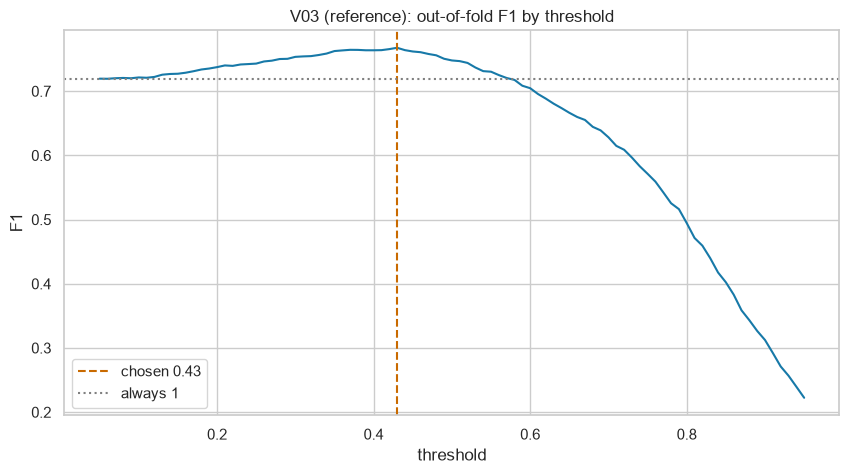

In [16]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(f1_curve.index, f1_curve.values, color=PLOT_BLUE)
ax.axvline(FINAL_THRESHOLD, color=PLOT_ORANGE, ls="--", label=f"chosen {FINAL_THRESHOLD:.2f}")
ax.axhline(f1_score(y[covered], np.ones(covered.sum())), color="grey", ls=":", label="always 1")
ax.set(title=f"{FINAL}: out-of-fold F1 by threshold", xlabel="threshold", ylabel="F1")
ax.legend()
plt.show()

**Reading**

- **No candidate passes the rule, so V03 stays the final model.** The closest, the blend logistic + boosting, is +0.008 on the official folds and +0.004 on the 8 folds, both at 1.8–1.9 SEM.
- **The threshold and the honest F1 are those of V03** (0.43, 0.802), which confirms that this notebook reproduces the V03 pipeline exactly.
- This is the outcome the rule was declared for: a gain of 0.004–0.008 ROC AUC that cannot be told apart from luck does not justify a more complex model.

# <font color='#E8800A'>8. Submission</font> <a class="anchor" id="submit"></a>
[Back to TOC](#toc)

The final pipeline is refitted on **all** train rows and predicts test with the final threshold. `submit` checks the file, saves it and logs it in `docs/submissions.md`: if the predictions are identical to an existing submission (for example V03), that version is reused instead of creating a new one.

In [17]:
final_model = clone(final_pipeline).fit(X_full, y)
proba = final_model.predict_proba(test.copy())[:, 1]
submission = pd.DataFrame({"ID": test.index, TARGET: (proba >= FINAL_THRESHOLD).astype(int)})
check_submission(submission)

v03_file = pd.read_csv(submission_path(3))
pd.Series({"share of 1s": submission[TARGET].mean(),
           "same label as V03": (submission[TARGET].to_numpy() == v03_file[TARGET].to_numpy()).mean()},
          name=FINAL).to_frame().style.format("{:.3f}")

,V03 (reference)
share of 1s,0.736
same label as V03,1.000


In [18]:
CONFIG = {"logistic regression": lr_table.loc[0, "configuration"], "KNN": knn_table.loc[0, "configuration"],
          "gradient boosting": gb_table.loc[0, "configuration"]}

if FINAL == "V03 (reference)":
    version = 3
    print("V03 stays the final model: nothing new to submit.")
else:
    version = submit(
        submission,
        notebook="tuning_ludovico",
        model=f"{FINAL} ({CONFIG.get(FINAL, 'members tuned as in this notebook')})",
        cv_f1=final_f1,
        notes=(f"tuned on official folds, checked on 8 half-year folds; threshold {FINAL_THRESHOLD:.2f}; "
               f"CV ROC AUC {final_scores['ROC AUC'].mean():.3f}; {submission[TARGET].mean():.0%} predicted 1"),
    )

V03 stays the final model: nothing new to submit.


**Reserve the version on GitHub, then upload the file on Kaggle** (uncomment when ready):

In [19]:
# version = publish(version)
# record_kaggle_score(version, 0.0)   # <- public score after the upload
# publish(version)

# <font color='#E8800A'>9. Summary</font> <a class="anchor" id="summary"></a>
[Back to TOC](#toc)

| Model | Untuned ROC AUC | Tuned ROC AUC | Gain from tuning (8-fold check) | vs V03 (official / 8 folds) |
|---|---|---|---|---|
| Logistic regression (+ L1) | 0.785 (0.796 = V03) | 0.799 | +0.006 ± 0.006 | +0.004 / +0.001, noise |
| KNN | 0.776 | 0.789 | **+0.016 ± 0.004** | −0.007 / −0.008, noise |
| Gradient boosting | 0.774 | 0.802 | **+0.016 ± 0.005** | +0.006 / +0.000, noise |
| Blend logistic + boosting | | **0.804** | | +0.008 / +0.004, **1.8–1.9 SEM** |

**Decision:** **V03 stays the final model** (honest F1 0.802, Kaggle 0.804). No new submission: the tuned pipeline would give identical predictions.

**For the report**
- Tuning matters a lot for the flexible models (boosting +0.028, KNN +0.013 on the official folds, confirmed on 8 folds) and little for the regularised logistic regression, which was already near its best.
- After tuning, the five-algorithm comparison ends in a tie at the top: a simple linear model with L1 selection is as good as a tuned ensemble on these 6,500 rows.
- The blend logistic + boosting is the only candidate close to a real gain. With more validation folds, or as the team's final ensemble, it is the first thing to reconsider.

# <font color='#E8800A'>10. Exploratory submission: the blend</font> <a class="anchor" id="explore"></a>
[Back to TOC](#toc)

The blend logistic + boosting is the strongest candidate (§5–§6) but did not pass the rule, so it is **not** the final model. It is submitted **for information only**: a Kaggle score is one noisy sample (±0.02 on the public leaderboard) and does not change the decision of §7. Same rules as every submission: threshold = best F1 on the out-of-fold predictions of all official folds, honest F1 = threshold from folds 1–2 scored on fold 3.

In [20]:
BLEND = "blend: logistic + boosting"
blend_oof = oof_tuned[BLEND]
blend_covered = blend_oof.notna()
BLEND_THRESHOLD, _ = best_threshold(y[blend_covered], blend_oof[blend_covered])
blend_f1, blend_t_early = honest_f1(blend_oof)

pd.Series({"ROC AUC (official folds)": f"{tuned_folds[BLEND].mean():.4f}",
           "final threshold (all folds)": f"{BLEND_THRESHOLD:.2f}",
           "threshold from folds 1-2": f"{blend_t_early:.2f}",
           "honest F1 (fold 3)": f"{blend_f1:.3f}",
           "V03 for comparison": "ROC AUC 0.7958, honest F1 0.802, Kaggle 0.804"}, name=BLEND).to_frame()

,blend: logistic + boosting
ROC AUC (official folds),0.8037
final threshold (all folds),0.39
threshold from folds 1-2,0.42
honest F1 (fold 3),0.803
V03 for comparison,"ROC AUC 0.7958, honest F1 0.802, Kaggle 0.804"


In [21]:
blend_model = clone(tuned[BLEND]).fit(X_full, y)
blend_proba = blend_model.predict_proba(test.copy())[:, 1]
blend_submission = pd.DataFrame({"ID": test.index, TARGET: (blend_proba >= BLEND_THRESHOLD).astype(int)})
check_submission(blend_submission)

pd.Series({"share of 1s": blend_submission[TARGET].mean(),
           "same label as V03": (blend_submission[TARGET].to_numpy() == v03_file[TARGET].to_numpy()).mean()},
          name=BLEND).to_frame().style.format("{:.3f}")

,blend: logistic + boosting
share of 1s,0.778
same label as V03,0.928


In [22]:
blend_version = submit(
    blend_submission,
    notebook="tuning_ludovico",
    model=(f"EXPLORATORY blend (soft vote) of tuned logistic ({CONFIG['logistic regression']}) "
           f"+ tuned boosting ({CONFIG['gradient boosting']})"),
    cv_f1=blend_f1,
    notes=(f"not the final model (did not pass the 2-SEM rule vs V03); threshold {BLEND_THRESHOLD:.2f}; "
           f"CV ROC AUC {tuned_folds[BLEND].mean():.3f}; {blend_submission[TARGET].mean():.0%} predicted 1"),
)

V05 saved as submissions/ML_Group_41_Version05.csv and logged:
  Version: 05 | Date: 2026-10-20 | Author: Ludovico Piras | Notebook / model: tuning_ludovico · EXPLORATORY blend (soft vote) of tuned logistic (C=0.03, select=L1 C=0.02) + tuned boosting (min_samples_leaf=200, max_leaf_nodes=31, max_iter=100, max_features=0.5, learning_rate=0.05, l2_regularization=10.0) | CV F1: 0.803 | Notes: not the final model (did not pass the 2-SEM rule vs V03); threshold 0.39; CV ROC AUC 0.804; 78% predicted 1
Next: publish(5) to reserve the version, then upload the file on Kaggle.


**Reserve the version, upload, record the score** (uncomment when ready):

In [23]:
# blend_version = publish(blend_version)
# record_kaggle_score(blend_version, 0.0)   # <- public score after the upload
# publish(blend_version)

**Reading**

- **Honest F1 0.803 against 0.802 for V03:** the ranking gain (+0.008 ROC AUC) barely reaches the thresholded F1. The expected Kaggle score is therefore about the same as V03 (0.804).
- **The blend changes 7% of the labels** compared with V03 and predicts 1 slightly more often (78% against 74%).
- **How to read the Kaggle score:** within ±0.02 of 0.804 it is a tie and confirms the validation. It does not justify replacing V03 on its own, because the public leaderboard is a small, noisy sample.